# Scrutineer: exploring the data and building the rules

This notebook shows how the requirements in `rules/requirements.yaml` were developed:
first looking at the real recordings, then checking each rule against the data before
writing it down, and finally testing the checks with fault injection and evaluating the
AI rule drafting.

Each rule followed the same steps: write down what the documentation or regulation says,
predict what the data should show, look at the data, and only then decide the rule and
its parameters.

**Data:** ZTBus dataset by Widmer, Ritter and Onder (ETH Zurich),
https://doi.org/10.3929/ethz-b-000626723, CC BY 4.0. The notebook uses the full sample
files in `data/` if they exist, and otherwise the compressed copies in `app/sample_data/`.

**To run it:** install the project with `pip install -e .` from the project root, then
run all cells from the top.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from scrutineer.data import find_journey_files, load_journey
from scrutineer.schema import DOCUMENTED_COLUMNS

DATA_DIR = Path("../data") if Path("../data").exists() else Path("../app/sample_data")
files = find_journey_files(DATA_DIR)
print(len(files), "journey files found in", DATA_DIR)

10 journey files found in ..\data


## The sample journeys

Each file is one driving mission: one bus, one day of regular service, one row per second.
The file name contains the bus number and the start and end time in UTC.

In [2]:
rows = []
for p in files:
    bus, d1, t1, d2, t2 = p.name.split(".")[0].split("_")
    rows.append({
        "file": p.name.split(".")[0],
        "bus": bus,
        "start": pd.to_datetime(f"{d1} {t1.replace('-', ':')}", utc=True),
        "end": pd.to_datetime(f"{d2} {t2.replace('-', ':')}", utc=True),
    })

catalog = pd.DataFrame(rows).sort_values("start").reset_index(drop=True)
catalog["hours"] = ((catalog["end"] - catalog["start"]).dt.total_seconds() / 3600).round(2)
catalog

,file,bus,start,end,hours
0,B183_2019-06-24_03-16-13_2019-06-24_18-54-06,B183,2019-06-24 03:16:13+00:00,2019-06-24 18:54:06+00:00,15.63
1,B183_2020-07-19_03-04-41_2020-07-19_21-04-28,B183,2020-07-19 03:04:41+00:00,2020-07-19 21:04:28+00:00,18.00
2,B208_2021-05-27_04-09-18_2021-05-27_18-21-41,B208,2021-05-27 04:09:18+00:00,2021-05-27 18:21:41+00:00,14.21
3,B183_2021-07-26_03-53-27_2021-07-26_07-18-47,B183,2021-07-26 03:53:27+00:00,2021-07-26 07:18:47+00:00,3.42
4,B208_2021-09-25_05-59-40_2021-09-25_18-15-31,B208,2021-09-25 05:59:40+00:00,2021-09-25 18:15:31+00:00,12.26
5,B183_2021-10-05_13-53-20_2021-10-05_18-14-53,B183,2021-10-05 13:53:20+00:00,2021-10-05 18:14:53+00:00,4.36
6,B208_2022-07-16_05-30-37_2022-07-16_18-19-51,B208,2022-07-16 05:30:37+00:00,2022-07-16 18:19:51+00:00,12.82
7,B208_2022-10-09_03-26-03_2022-10-09_22-56-13,B208,2022-10-09 03:26:03+00:00,2022-10-09 22:56:13+00:00,19.50
8,B208_2022-10-26_03-25-19_2022-10-26_23-02-09,B208,2022-10-26 03:25:19+00:00,2022-10-26 23:02:09+00:00,19.61
9,B208_2022-11-30_04-47-53_2022-11-30_19-50-22,B208,2022-11-30 04:47:53+00:00,2022-11-30 19:50:22+00:00,15.04


## First look at one journey

Before writing any rule, I checked whether the real files match the dataset paper's
description (Table 1): the columns, the missing values, the timing and the door flag.

In [3]:
path = files[0]
df = load_journey(path)
print("Using:", path.name)
print("Shape (rows, columns):", df.shape)
df.head()

Using: B183_2019-06-24_03-16-13_2019-06-24_18-54-06.csv
Shape (rows, columns): (56274, 26)


,time_iso,time_unix,electric_powerDemand,gnss_altitude,gnss_course,gnss_latitude,gnss_longitude,itcs_busRoute,itcs_numberOfPassengers,itcs_stopName,...,odometry_wheelSpeed_mr,odometry_wheelSpeed_rl,odometry_wheelSpeed_rr,status_doorIsOpen,status_gridIsAvailable,status_haltBrakeIsActive,status_parkBrakeIsActive,temperature_ambient,traction_brakePressure,traction_tractionForce
0,2019-06-24 03:16:13+00:00,1561346173,0.0,393.2,2.17119,0.826972,0.148489,-,NaN,-,...,0.0,0.0,0.0,1,0,0,1,296.15,246666.7,0.0
1,2019-06-24 03:16:14+00:00,1561346174,0.0,393.2,2.17119,0.826972,0.148489,-,NaN,-,...,0.0,0.0,0.0,1,0,0,1,296.15,246666.7,0.0
2,2019-06-24 03:16:15+00:00,1561346175,0.0,393.2,2.17119,0.826972,0.148489,-,NaN,-,...,0.0,0.0,0.0,1,0,0,1,296.15,246666.7,0.0
3,2019-06-24 03:16:16+00:00,1561346176,-0.0,393.2,2.17119,0.826972,0.148489,-,NaN,-,...,0.0,0.0,0.0,1,0,0,1,296.15,246666.7,0.0
4,2019-06-24 03:16:17+00:00,1561346177,-0.0,393.2,2.17119,0.826972,0.148489,-,NaN,-,...,0.0,0.0,0.0,1,0,0,1,296.15,246666.7,0.0


### Do the columns match Table 1?

In [4]:
missing_cols = [c for c in DOCUMENTED_COLUMNS if c not in df.columns]
extra_cols = [c for c in df.columns if c not in DOCUMENTED_COLUMNS]
print("In Table 1 but missing from the file:", missing_cols)
print("In the file but not in Table 1:", extra_cols)
print("Same order as Table 1:", list(df.columns) == DOCUMENTED_COLUMNS)
df.dtypes

In Table 1 but missing from the file: []
In the file but not in Table 1: []
Same order as Table 1: True


time_iso                      datetime64[us, UTC]
time_unix                                   int64
electric_powerDemand                      float64
gnss_altitude                             float64
gnss_course                               float64
gnss_latitude                             float64
gnss_longitude                            float64
itcs_busRoute                                 str
itcs_numberOfPassengers                   float64
itcs_stopName                                 str
odometry_articulationAngle                float64
odometry_steeringAngle                    float64
odometry_vehicleSpeed                     float64
odometry_wheelSpeed_fl                    float64
odometry_wheelSpeed_fr                    float64
odometry_wheelSpeed_ml                    float64
odometry_wheelSpeed_mr                    float64
odometry_wheelSpeed_rl                    float64
odometry_wheelSpeed_rr                    float64
status_doorIsOpen                           int64


All columns match.

### Missing values

In [5]:
nan_counts = df.isna().sum()
summary = pd.DataFrame({"missing": nan_counts, "percent": (nan_counts / len(df) * 100).round(2)})
print(summary[summary["missing"] > 0])

# The two text columns use "-" instead of NaN for unavailable data (Table 1)
for col in ["itcs_busRoute", "itcs_stopName"]:
    print(col, "unavailable ('-'):", (df[col] == "-").sum())

                         missing  percent
itcs_numberOfPassengers    55752    99.07
itcs_busRoute unavailable ('-'): 56274
itcs_stopName unavailable ('-'): 55752


Only the passenger, route and stop columns are mostly empty. The paper explains why:
this information is only attached when the bus leaves a stop. So these gaps are normal,
and the gap rule (REQ-005) must not check these columns.

### Is every row exactly one second after the previous one?

In [6]:
steps = df["time_unix"].diff().dropna()
print("Rows not exactly 1 s after the previous row:", int((steps != 1).sum()))
print("Sorted in time:", df["time_unix"].is_monotonic_increasing)
print("Duplicate timestamps:", int(df["time_unix"].duplicated().sum()))
print("Duration (hours):", round((df["time_unix"].iloc[-1] - df["time_unix"].iloc[0]) / 3600, 2))

Rows not exactly 1 s after the previous row: 0
Sorted in time: True
Duplicate timestamps: 0
Duration (hours): 15.63


### What does the door flag look like?

In [7]:
is_open = df["status_doorIsOpen"] == 1
speed_kmh = df["odometry_vehicleSpeed"] * 3.6   # the column is in m/s

print("Share of time with a door open (%):", round(is_open.mean() * 100, 1))
print("Speed in km/h while a door is open:")
print(speed_kmh[is_open].describe().round(2))
print("Rows with a door open and speed above 5 km/h:", int((is_open & (speed_kmh > 5)).sum()))

Share of time with a door open (%): 16.3
Speed in km/h while a door is open:
count    9166.00
mean       -0.00
std         0.01
min        -0.29
25%         0.00
50%         0.00
75%         0.00
max         0.26
Name: odometry_vehicleSpeed, dtype: float64
Rows with a door open and speed above 5 km/h: 0


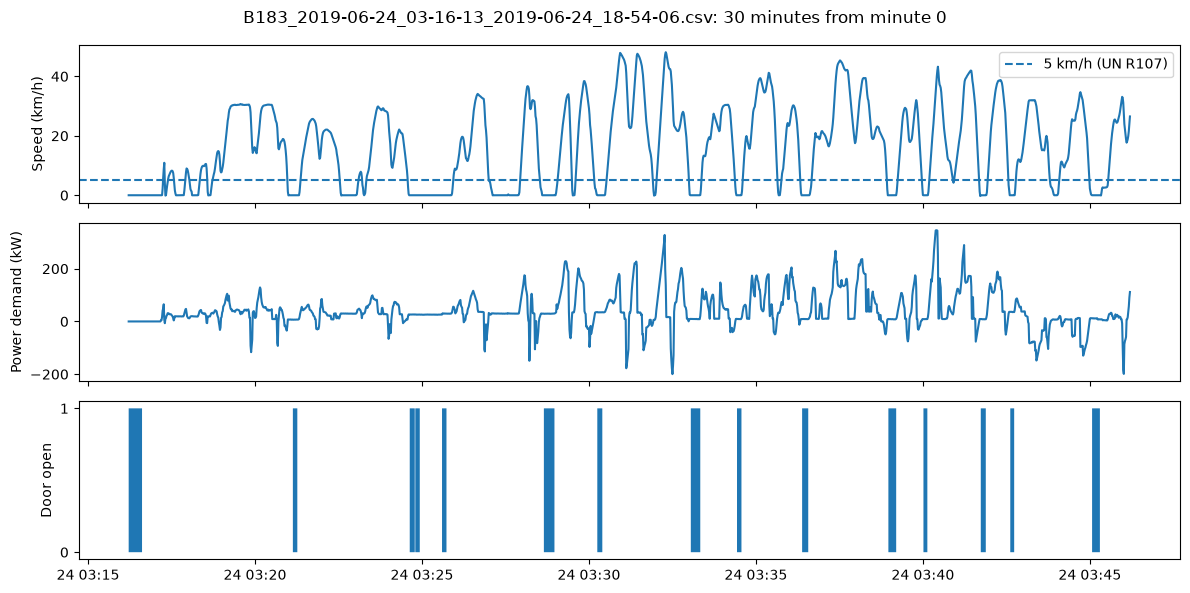

In [8]:
minutes, start_min = 30, 0   # change these to look at other parts of the journey
w = df.iloc[start_min * 60 : (start_min + minutes) * 60]
t = w["time_iso"]

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, w["odometry_vehicleSpeed"] * 3.6)
axes[0].axhline(5, linestyle="--", label="5 km/h (UN R107)")
axes[0].set_ylabel("Speed (km/h)")
axes[0].legend(loc="upper right")
axes[1].plot(t, w["electric_powerDemand"] / 1000)
axes[1].set_ylabel("Power demand (kW)")
axes[2].fill_between(t, 0, (w["status_doorIsOpen"] == 1).astype(int), step="post")
axes[2].set_ylabel("Door open")
axes[2].set_yticks([0, 1])
fig.suptitle(f"{path.name}: {minutes} minutes from minute {start_min}")
plt.tight_layout()
plt.show()

Each door opening (bottom) happens while the bus is standing still (top), far below
the 5 km/h limit. The power demand (middle) drops below zero when the bus brakes,
stays low while it stands at a stop, and rises sharply when it pulls away again.

## REQ-001: no door open above 5 km/h

**Source:** UN Regulation No. 107, Annex 3: power-operated doors must be prevented from
opening while the vehicle moves faster than 5 km/h.

The first journey already showed that doors only open when the bus is essentially standing
still. Running the check on all journeys:

In [9]:
from scrutineer.checks import check_door_speed

results = []
for p in files:
    r = check_door_speed(load_journey(p))
    results.append({"file": p.name[:15], "status": r.status, "rows": r.rows_total,
                    "rows_evaluated": r.rows_evaluated, "violations": len(r.violations)})
pd.DataFrame(results)

,file,status,rows,rows_evaluated,violations
0,B183_2019-06-24,PASS,56274,56274,0
1,B183_2020-07-19,PASS,64788,64788,0
2,B183_2021-07-26,PASS,12321,12321,0
3,B183_2021-10-05,PASS,15694,15694,0
4,B208_2021-05-27,PASS,51144,51144,0
5,B208_2021-09-25,PASS,44152,44152,0
6,B208_2022-07-16,PASS,46155,46155,0
7,B208_2022-10-09,PASS,70211,70211,0
8,B208_2022-10-26,PASS,70611,70611,0
9,B208_2022-11-30,PASS,54150,54150,0


### Blank values on the last row

In the first version of this check, 3 of the 10 journeys came back INCONCLUSIVE, because
any missing door value blocked a PASS. Looking closer, each of those files has exactly one
blank door flag, on the very last row:

In [10]:
for p in files:
    d = load_journey(p)
    blank_rows = d.index[d["status_doorIsOpen"].isna()].tolist()
    if blank_rows:
        print(p.name[:15], "| blank door flag at rows", blank_rows, "| last row is", len(d) - 1)

B183_2021-07-26 | blank door flag at rows [12320] | last row is 12320
B208_2021-05-27 | blank door flag at rows [51143] | last row is 51143
B208_2022-10-26 | blank door flag at rows [70610] | last row is 70610


At those moments the bus was not moving fast, so the blank value could not hide a violation.
This led to a design decision for all checks: **a missing value only makes the result
INCONCLUSIVE if it could change the answer** (`could_hide_violation` in `checks.py`).
With that change, all 10 journeys pass, as shown above.

## REQ-002: halt brake active after 3 s of standstill

**Source:** Table 1 of the dataset paper says the halt brake is activated automatically
whenever the bus stands still.

**My prediction:** the halt brake flag is 1 whenever the speed is 0 or below.

Testing that on the first journey:

In [11]:
d = load_journey(files[0])
brake = d["status_haltBrakeIsActive"] == 1
stopped = d["odometry_vehicleSpeed"] <= 0

print("rows with speed <= 0:", int(stopped.sum()))
print("share of those with the brake active (%):", round(brake[stopped].mean() * 100, 1))
print("rows where the brake is ever active:", int(brake.sum()))

rows with speed <= 0: 19746
share of those with the brake active (%): 0.0
rows where the brake is ever active: 0


The brake flag is never active in this journey, which contradicts the paper.
Checking all journeys, with the brake line pressure as a physical cross-check:

In [12]:
rows = []
for p in files:
    d = load_journey(p)
    stopped = d["odometry_vehicleSpeed"] <= 0
    rows.append({
        "file": p.name[:15],
        "halt_values": sorted(d["status_haltBrakeIsActive"].unique().tolist()),
        "halt_on_pct": round((d["status_haltBrakeIsActive"] == 1).mean() * 100, 2),
        "brakePressure_stopped": round(d.loc[stopped, "traction_brakePressure"].median(), 1),
        "brakePressure_moving": round(d.loc[~stopped, "traction_brakePressure"].median(), 1),
    })
pd.DataFrame(rows)

,file,halt_values,halt_on_pct,brakePressure_stopped,brakePressure_moving
0,B183_2019-06-24,[0],0.00,244166.7,0.0
1,B183_2020-07-19,"[0, 1]",31.99,243333.3,0.0
2,B183_2021-07-26,"[0.0, 1.0, nan]",35.72,241808.3,0.0
3,B183_2021-10-05,"[0, 1]",29.96,241900.0,0.0
4,B208_2021-05-27,"[0.0, 1.0, nan]",33.88,243333.3,0.0
5,B208_2021-09-25,"[0, 1]",35.29,244166.7,0.0
6,B208_2022-07-16,"[0, 1]",32.26,243333.3,0.0
7,B208_2022-10-09,"[0, 1]",32.15,244166.7,0.0
8,B208_2022-10-26,"[0.0, 1.0, nan]",30.20,242540.2,0.0
9,B208_2022-11-30,"[0, 1]",31.86,243333.3,0.0


Only the 2019 journey has a dead flag. The brake pressure at standstill is similar in all
journeys, so the flag appears not to have been recorded there. For such a journey the check
returns INCONCLUSIVE, because a signal that never changes cannot confirm or break the rule.

### How quickly does the brake come on?

For every stop in the journeys where the flag works: how many seconds after the stop starts
does the brake come on?

In [13]:
lags, never_lengths = [], []
for p in files:
    d = load_journey(p)
    halt = d["status_haltBrakeIsActive"] == 1
    if not halt.any():
        continue  # the flag is dead in this file
    stopped = d["odometry_vehicleSpeed"] <= 0
    run_id = (stopped != stopped.shift(fill_value=False)).cumsum()
    for _, block in d[stopped].groupby(run_id[stopped]):
        h = halt[block.index]
        if h.any():
            lags.append(int(h.values.argmax()))   # seconds from stop start to brake on
        else:
            never_lengths.append(len(block))      # how long that stop lasted

lags = pd.Series(lags)
print("stops where the brake came on:", len(lags))
print(lags.value_counts().sort_index())
print("share within 3 s:", round((lags <= 3).mean() * 100, 2), "%")
print("stops where the brake never came on:", len(never_lengths))

stops where the brake came on: 5285
0     1692
1     2840
2      682
3       63
4        4
6        1
9        1
16       1
20       1
Name: count, dtype: int64
share within 3 s: 99.85 %
stops where the brake never came on: 367


99.85% of the stops where the brake came on did so within 3 seconds, so the rule uses a
**3-second grace period**, observed from this data. Most stops where the brake never came on
lasted only 1 to 3 seconds and are ignored by the grace period.

The longer ones, where the brake never came on:

In [14]:
long_never = []
for p in files:
    d = load_journey(p)
    halt = d["status_haltBrakeIsActive"] == 1
    if not halt.any():
        continue
    stopped = d["odometry_vehicleSpeed"] <= 0
    run_id = (stopped != stopped.shift(fill_value=False)).cumsum()
    for _, b in d[stopped].groupby(run_id[stopped]):
        if len(b) > 3 and not halt[b.index].any():
            long_never.append({
                "file": p.name[:15],
                "seconds": len(b),
                "rows_from_journey_start": int(b.index[0]),
                "rows_to_journey_end": int(len(d) - 1 - b.index[-1]),
                "park_brake_on_pct": round((b["status_parkBrakeIsActive"] == 1).mean() * 100),
                "brake_pressure_median_Pa": round(b["traction_brakePressure"].median()),
                "door_open_pct": round((b["status_doorIsOpen"] == 1).mean() * 100),
            })
pd.DataFrame(long_never).sort_values("seconds", ascending=False)

,file,seconds,rows_from_journey_start,rows_to_journey_end,park_brake_on_pct,brake_pressure_median_Pa,door_open_pct
34,B208_2022-10-26,106,44273,26232,0,0,0
12,B183_2020-07-19,34,38759,25995,0,96814,0
35,B208_2022-10-26,32,44380,26199,0,0,0
29,B208_2022-10-26,31,38781,31799,0,0,0
24,B208_2022-10-09,22,28661,41528,0,4167,0
36,B208_2022-10-26,20,44646,25945,0,0,0
13,B183_2020-07-19,20,44843,19925,0,91667,0
37,B208_2022-10-26,19,46967,23625,0,0,0
11,B183_2020-07-19,19,37390,27379,0,48333,0
9,B183_2020-07-19,16,32803,31969,0,73333,0


These stops happen in the middle of journeys, with the park brake off and no door open.
The data alone cannot explain them, so they are reported as candidate events, not as faults.

Running the check:

In [15]:
from scrutineer.checks import check_halt_brake

results = []
for p in files:
    r = check_halt_brake(load_journey(p))
    results.append({
        "file": p.name[:15],
        "status": r.status,
        "violations": len(r.violations),
        "longest_stop_without_brake_s": max((v.worst_value for v in r.violations), default=None),
        "note": r.note,
    })
summary = pd.DataFrame(results)
print("total violations:", summary["violations"].sum())
summary

total violations: 52


,file,status,violations,longest_stop_without_brake_s,note
0,B183_2019-06-24,INCONCLUSIVE,0,NaN,halt brake flag is never active in this recording
1,B183_2020-07-19,FAIL,20,37.0,
2,B183_2021-07-26,FAIL,1,5.0,
3,B183_2021-10-05,FAIL,4,14.0,
4,B208_2021-05-27,FAIL,1,21.0,
5,B208_2021-09-25,FAIL,4,15.0,
6,B208_2022-07-16,PASS,0,NaN,
7,B208_2022-10-09,FAIL,3,22.0,
8,B208_2022-10-26,FAIL,18,106.0,
9,B208_2022-11-30,FAIL,1,12.0,


## REQ-003: no traction force while a door is open

**Source:** derived from UN R107 (para 2.27 and Annex 3 para 7.6.5.9): driving away from rest
with a door not fully closed must be prevented, or the driver warned. This rule checks the
prevention behaviour, since a warning is not recorded in the data.

**My prediction:** with a door open, the traction force is 0 or a little above.

In [16]:
rows = []
for p in files:
    d = load_journey(p)
    door = d["status_doorIsOpen"] == 1
    f = d["traction_tractionForce"]
    moving = d["odometry_vehicleSpeed"] * 3.6 > 5
    rows.append({
        "file": p.name[:15],
        "force_door_open_min": round(f[door].min()),
        "force_door_open_median": round(f[door].median()),
        "force_door_open_p99": round(f[door].quantile(0.99)),
        "force_door_open_max": round(f[door].max()),
        "force_moving_median": round(f[moving].median()),
    })
pd.DataFrame(rows)

,file,force_door_open_min,force_door_open_median,force_door_open_p99,force_door_open_max,force_moving_median
0,B183_2019-06-24,-22,0,0,11279,1798
1,B183_2020-07-19,-15,0,0,14679,478
2,B183_2021-07-26,-17,0,0,1,13
3,B183_2021-10-05,-16,0,0,7954,2641
4,B208_2021-05-27,-19,0,0,4,39
5,B208_2021-09-25,-88,0,0,12545,1935
6,B208_2022-07-16,-30,0,0,14205,1759
7,B208_2022-10-09,-30,0,0,15391,872
8,B208_2022-10-26,-27,0,0,10865,1383
9,B208_2022-11-30,-26,0,0,11576,1179


In at least 99% of door-open rows the force is 0 N or less, but most journeys have rare
moments of thousands of newtons. When do they happen?

In [17]:
rows = []
for p in files:
    d = load_journey(p)
    door = d["status_doorIsOpen"] == 1
    f = d["traction_tractionForce"]
    high = door & (f > 100)
    # door-open rows within the last 2 seconds before the door closes
    near_close = door & (~door.shift(-1, fill_value=False) | ~door.shift(-2, fill_value=False))
    rows.append({
        "file": p.name[:15],
        "rows_force_over_100": int(high.sum()),
        "of_those_near_close": int((high & near_close).sum()),
        "max_speed_kmh_at_those": round((d.loc[high, "odometry_vehicleSpeed"] * 3.6).max(), 2) if high.any() else None,
    })
pd.DataFrame(rows)

,file,rows_force_over_100,of_those_near_close,max_speed_kmh_at_those
0,B183_2019-06-24,25,25,0.26
1,B183_2020-07-19,25,25,0.34
2,B183_2021-07-26,0,0,NaN
3,B183_2021-10-05,19,19,0.47
4,B208_2021-05-27,0,0,NaN
5,B208_2021-09-25,21,21,0.23
6,B208_2022-07-16,28,28,0.29
7,B208_2022-10-09,21,21,0.20
8,B208_2022-10-26,39,39,0.36
9,B208_2022-11-30,26,26,0.40


Every moment above 100 N falls in the last 2 seconds before the door closes, at speeds below
0.5 km/h: the bus starting to pull away as the door closes. So the rule uses a limit of
**100 N** and excuses the **last 2 seconds before the door closes**, both observed from this data.
The trade-off: a fault in which the drive pushes only in those 2 seconds would be missed.

In [18]:
from scrutineer.checks import check_door_traction

results = []
for p in files:
    r = check_door_traction(load_journey(p))
    results.append({"file": p.name[:15], "status": r.status, "violations": len(r.violations)})
pd.DataFrame(results)

,file,status,violations
0,B183_2019-06-24,PASS,0
1,B183_2020-07-19,PASS,0
2,B183_2021-07-26,PASS,0
3,B183_2021-10-05,PASS,0
4,B208_2021-05-27,PASS,0
5,B208_2021-09-25,PASS,0
6,B208_2022-07-16,PASS,0
7,B208_2022-10-09,PASS,0
8,B208_2022-10-26,PASS,0
9,B208_2022-11-30,PASS,0


## REQ-004: power demand within the documented range

**Source:** the paper's "Statistical analysis" section: two motors with about 320 kW combined
in each direction, plus 20 to 30 kW for auxiliary systems, which gives roughly -320 to +350 kW.

In [19]:
rows = []
for p in files:
    kw = load_journey(p)["electric_powerDemand"] / 1000   # the column is in watts
    rows.append({"file": p.name[:15], "min_kw": round(kw.min(), 1), "max_kw": round(kw.max(), 1),
                 "rows_above_350": int((kw > 350).sum())})
pd.DataFrame(rows)

,file,min_kw,max_kw,rows_above_350
0,B183_2019-06-24,-286.3,361.7,43
1,B183_2020-07-19,-303.7,360.2,20
2,B183_2021-07-26,-186.2,301.0,0
3,B183_2021-10-05,-234.8,344.4,0
4,B208_2021-05-27,-279.3,350.5,1
5,B208_2021-09-25,-296.5,347.0,0
6,B208_2022-07-16,-271.6,354.8,7
7,B208_2022-10-09,-308.6,358.0,1
8,B208_2022-10-26,-310.2,358.9,11
9,B208_2022-11-30,-236.2,356.5,3


7 of 10 journeys go slightly above 350 kW, by up to 11.7 kW, during normal acceleration.
Since the paper's figures are approximate, the rule adds a 20 kW margin on each side:
**-340 to +370 kW**. This margin was chosen after seeing the data.

In [20]:
from scrutineer.checks import check_power_range

results = []
for p in files:
    r = check_power_range(load_journey(p))
    results.append({"file": p.name[:15], "status": r.status, "violations": len(r.violations)})
pd.DataFrame(results)

,file,status,violations
0,B183_2019-06-24,PASS,0
1,B183_2020-07-19,PASS,0
2,B183_2021-07-26,PASS,0
3,B183_2021-10-05,PASS,0
4,B208_2021-05-27,PASS,0
5,B208_2021-09-25,PASS,0
6,B208_2022-07-16,PASS,0
7,B208_2022-10-09,PASS,0
8,B208_2022-10-26,PASS,0
9,B208_2022-11-30,PASS,0


## REQ-005: no signal gap of 10 s or more

**Source:** the paper's "Technical Validation" section: missions with a gap of 10 seconds or more
in the vehicle control unit data were rejected. GPS and passenger columns are left out, since they
can be missing in normal operation.

In [21]:
from scrutineer.checks import check_signal_gaps

results = []
for p in files:
    d = load_journey(p)
    r = check_signal_gaps(d)
    steps = d["time_unix"].diff().dropna()
    results.append({"file": p.name[:15], "status": r.status, "violations": len(r.violations),
                    "steps_not_1s": int((steps != 1).sum())})
pd.DataFrame(results)

,file,status,violations,steps_not_1s
0,B183_2019-06-24,PASS,0,0
1,B183_2020-07-19,PASS,0,0
2,B183_2021-07-26,PASS,0,0
3,B183_2021-10-05,PASS,0,0
4,B208_2021-05-27,PASS,0,0
5,B208_2021-09-25,PASS,0,0
6,B208_2022-07-16,PASS,0,0
7,B208_2022-10-09,PASS,0,0
8,B208_2022-10-26,PASS,0,0
9,B208_2022-11-30,PASS,0,0


All journeys pass, which confirms the paper's claim for this sample. The last column also shows
that every journey is sampled exactly once per second, which covers the timing rule that was
not implemented.

## All requirements together

The engine reads `rules/requirements.yaml` and runs every requirement on every journey:

In [22]:
from scrutineer.engine import run_on_journeys

table = run_on_journeys(files, "../rules/requirements.yaml")
table.pivot(index="journey", columns="requirement", values="status")

requirement,REQ-001,REQ-002,REQ-003,REQ-004,REQ-005
journey,,,,,
B183_2019-06-24,PASS,INCONCLUSIVE,PASS,PASS,PASS
B183_2020-07-19,PASS,FAIL,PASS,PASS,PASS
B183_2021-07-26,PASS,FAIL,PASS,PASS,PASS
B183_2021-10-05,PASS,FAIL,PASS,PASS,PASS
B208_2021-05-27,PASS,FAIL,PASS,PASS,PASS
B208_2021-09-25,PASS,FAIL,PASS,PASS,PASS
B208_2022-07-16,PASS,PASS,PASS,PASS,PASS
B208_2022-10-09,PASS,FAIL,PASS,PASS,PASS
B208_2022-10-26,PASS,FAIL,PASS,PASS,PASS


## Fault injection

Known faults are planted into copies of the journeys, 5 times per journey (fixed seed).
A fault counts as caught only if the target rule reports a violation in the changed rows.
This takes a minute or two.

In [23]:
from scrutineer.injection import run_campaign, summarize

trials = run_campaign(files, "../rules/requirements.yaml")
summarize(trials)

,fault,target,expected,trials,caught,missed,catch_rate_%
0,door stuck open,REQ-001,caught,50,50,0,100.0
1,"drive pushes, door open",REQ-003,caught,50,50,0,100.0
2,power spike,REQ-004,caught,50,50,0,100.0
3,long speed dropout (15 s),REQ-005,caught,50,50,0,100.0
4,short speed dropout (5 s),REQ-005,missed,50,0,50,0.0
5,frozen speed (20 s),none,missed,50,0,50,0.0
6,brake signal lost,REQ-002,caught,45,45,0,100.0


Which other rules reacted to each fault:

In [24]:
trials.groupby("fault")["other_rules_changed"].value_counts()

fault                      other_rules_changed
brake signal lost                                 45
door stuck open            REQ-003                27
                                                  23
drive pushes, door open                           50
frozen speed (20 s)                               50
long speed dropout (15 s)                         29
                           REQ-001                21
power spike                                       50
short speed dropout (5 s)                         38
                           REQ-001                12
Name: count, dtype: int64

## AI rule drafting

A language model turns requirement sentences into rule entries, which code validates and a person
approves. Running the evaluation calls the Gemini API and needs a key in `.env`, so by default this
section shows the saved results. Set `RUN_AI = True` to run it again; the results can vary between runs.

In [25]:
RUN_AI = False

if RUN_AI:
    from scrutineer.ai import draft_rule, evaluate_drafting

    print(draft_rule("While the park brake is active, the vehicle speed must not exceed 1 km/h.").summary())
    ai_results = evaluate_drafting("../evaluation/rule_drafting_cases.yaml")
else:
    ai_results = pd.read_csv("../app/results/ai_evaluation.csv")

print(f"{ai_results['passed'].sum()} of {len(ai_results)} correct")
ai_results[["sentence", "outcome", "parameters"]]

17 of 18 correct


,sentence,outcome,parameters
0,No door may be open while the bus moves faster...,correct,"{'flag': 'status_doorIsOpen', 'signal': 'odome..."
1,"While any door is open, the vehicle speed must...",correct,"{'flag': 'status_doorIsOpen', 'signal': 'odome..."
2,"While the park brake is active, the vehicle sp...",correct,"{'flag': 'status_parkBrakeIsActive', 'signal':..."
3,"While the halt brake is active, the traction f...",correct,"{'flag': 'status_haltBrakeIsActive', 'signal':..."
4,While the bus is connected to the overhead gri...,correct,"{'flag': 'status_gridIsAvailable', 'signal': '..."
5,The bus must not drive faster than 70 km/h.,wrong value for min_value,"{'signal': 'odometry_vehicleSpeed', 'min_value..."
6,Electric power demand must stay between -340 k...,correct,"{'signal': 'electric_powerDemand', 'min_value'..."
7,Traction force must never exceed 50 kN.,correct,"{'signal': 'traction_tractionForce', 'min_valu..."
8,Ambient temperature readings must stay between...,correct,"{'signal': 'temperature_ambient', 'min_value':..."
9,Brake line pressure must not exceed 8 bar.,correct,"{'signal': 'traction_brakePressure', 'min_valu..."
